# Breast Cancer Diagnostic Classifier: end-to-end Colab notebook

**Goal:** train, evaluate, test and serve a model that classifies tumours as malignant or benign.

**Note on this notebook:** this notebook was produced with help from Claude. These Claude-related notes appear only here; the GitHub repository contains none, by design.

**How to run:** `Runtime > Run all` on a fresh runtime. No GPU, no dataset upload and no API keys are needed (the dataset ships with scikit-learn). Total runtime is about one minute.

**Data flow:** `load -> validate -> stratified split -> cross-validate 4 models (train set only) -> refit best -> evaluate on test set -> save artifact -> predict / API`

## 1. Environment setup
Installs dependencies. Colab already has most; pinning minimums keeps runs reproducible.

In [1]:
!pip install -q 'scikit-learn>=1.4' 'pandas>=2.0' matplotlib joblib 'fastapi>=0.110' 'uvicorn>=0.29' 'httpx>=0.27' 'pytest>=8.0'
import sys, os
os.makedirs('bcproj/src/bcclf', exist_ok=True); os.makedirs('bcproj/tests', exist_ok=True)
os.chdir('bcproj'); sys.path.insert(0, 'src')
print('Working dir:', os.getcwd())

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

Working dir: /tmp/nbrun/bcproj


## 2. Write the project source files
Each cell below writes one module, so the notebook is self-contained and mirrors the GitHub layout exactly. Expected output per cell: `Writing ...`.

In [2]:
%%writefile src/bcclf/__init__.py
"""Breast cancer diagnostic classifier package."""

__version__ = "1.0.0"

Writing src/bcclf/__init__.py


### **config.py**: one place for seeds, split size and paths, overridable by environment variables.

In [3]:
%%writefile src/bcclf/config.py
"""Central configuration. Values can be overridden through environment variables."""
import os
from pathlib import Path

PROJECT_ROOT = Path(__file__).resolve().parents[2]
RANDOM_STATE = int(os.getenv("RANDOM_STATE", "42"))
TEST_SIZE = float(os.getenv("TEST_SIZE", "0.2"))
CV_FOLDS = int(os.getenv("CV_FOLDS", "5"))


def get_model_path() -> Path:
    """Resolve the model artifact path at call time so tests can override it."""
    return Path(os.getenv("MODEL_PATH", PROJECT_ROOT / "models" / "model.joblib"))


def get_reports_dir() -> Path:
    path = Path(os.getenv("REPORTS_DIR", PROJECT_ROOT / "reports"))
    path.mkdir(parents=True, exist_ok=True)
    return path

Writing src/bcclf/config.py


### **logging_config.py**: consistent log format for every entry point.

In [4]:
%%writefile src/bcclf/logging_config.py
"""Logging setup shared by all entry points."""
import logging
import os


def setup_logging() -> None:
    level = os.getenv("LOG_LEVEL", "INFO").upper()
    logging.basicConfig(
        level=level,
        format="%(asctime)s | %(levelname)-8s | %(name)s | %(message)s",
    )

Writing src/bcclf/logging_config.py


### **data.py**: loads the data and fails early on bad input. The split is *stratified* so train and test keep the same malignant/benign ratio.

In [5]:
%%writefile src/bcclf/data.py
"""Data loading, validation and splitting."""
import logging
from typing import Tuple

import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

from .config import RANDOM_STATE, TEST_SIZE

logger = logging.getLogger(__name__)


def load_dataset() -> Tuple[pd.DataFrame, pd.Series, list]:
    """Return features, target and class names (0 = malignant, 1 = benign)."""
    bunch = load_breast_cancer(as_frame=True)
    X, y = bunch.data, bunch.target
    validate_features(X)
    logger.info("Loaded dataset: %d rows, %d features", *X.shape)
    return X, y, [str(n) for n in bunch.target_names]


def validate_features(X: pd.DataFrame) -> None:
    """Fail early on empty, non-numeric or missing values."""
    if X.empty:
        raise ValueError("Feature table is empty.")
    if not all(pd.api.types.is_numeric_dtype(t) for t in X.dtypes):
        raise ValueError("All features must be numeric.")
    if X.isna().any().any():
        raise ValueError("Feature table contains missing values.")


def split_data(X: pd.DataFrame, y: pd.Series):
    """Stratified train/test split so class balance is preserved."""
    return train_test_split(
        X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
    )

Writing src/bcclf/data.py


### **model.py**: four candidates, each in a `Pipeline` with `StandardScaler`. Scaling lives inside the pipeline so it is fit on training folds only (prevents leakage). The SVM is wrapped in `CalibratedClassifierCV` to get reliable probabilities.

In [6]:
%%writefile src/bcclf/model.py
"""Model definitions. Every model is wrapped with scaling in one Pipeline."""
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from .config import RANDOM_STATE

CANDIDATES = {
    "logistic_regression": lambda: LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),
    "svm_rbf": lambda: CalibratedClassifierCV(SVC(random_state=RANDOM_STATE), ensemble=False),
    "random_forest": lambda: RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
    "gradient_boosting": lambda: GradientBoostingClassifier(random_state=RANDOM_STATE),
}


def build_pipeline(name: str) -> Pipeline:
    if name not in CANDIDATES:
        raise ValueError(f"Unknown model '{name}'. Choose from {sorted(CANDIDATES)}.")
    return Pipeline([("scaler", StandardScaler()), ("clf", CANDIDATES[name]())])

Writing src/bcclf/model.py


### **evaluate.py**: metrics focus on the *malignant* class, because missing a cancer (false negative) is costlier than a false alarm. Also saves confusion-matrix and ROC plots.

In [7]:
%%writefile src/bcclf/evaluate.py
"""Metrics and plots."""
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)


def compute_metrics(model, X_test, y_test) -> dict:
    """Class 0 (malignant) is the clinically important class, so its recall is reported."""
    pred = model.predict(X_test)
    proba_benign = model.predict_proba(X_test)[:, 1]
    return {
        "accuracy": float(accuracy_score(y_test, pred)),
        "precision_malignant": float(precision_score(y_test, pred, pos_label=0)),
        "recall_malignant": float(recall_score(y_test, pred, pos_label=0)),
        "f1_malignant": float(f1_score(y_test, pred, pos_label=0)),
        "roc_auc": float(roc_auc_score(y_test, proba_benign)),
    }


def save_plots(model, X_test, y_test, class_names, out_dir: Path) -> None:
    fig, ax = plt.subplots(figsize=(4.5, 4))
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test, display_labels=class_names, ax=ax, colorbar=False
    )
    ax.set_title("Confusion matrix (test set)")
    fig.tight_layout()
    fig.savefig(out_dir / "confusion_matrix.png", dpi=120)
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(4.5, 4))
    RocCurveDisplay.from_estimator(model, X_test, y_test, ax=ax)
    ax.set_title("ROC curve (test set)")
    fig.tight_layout()
    fig.savefig(out_dir / "roc_curve.png", dpi=120)
    plt.close(fig)

Writing src/bcclf/evaluate.py


### **train.py**: cross-validates all candidates on the training set, picks the best by ROC-AUC, refits it, scores it once on the untouched test set and saves everything.

In [8]:
%%writefile src/bcclf/train.py
"""Training entry point: compare candidates by cross-validation, refit best, evaluate, save."""
import argparse
import json
import logging

import joblib
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_validate

from .config import CV_FOLDS, RANDOM_STATE, get_model_path, get_reports_dir
from .data import load_dataset, split_data
from .evaluate import compute_metrics, save_plots
from .logging_config import setup_logging
from .model import CANDIDATES, build_pipeline

logger = logging.getLogger(__name__)


def compare_models(X_train, y_train, names=None) -> pd.DataFrame:
    """Cross-validate each candidate on the training set only (no test leakage)."""
    cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
    rows = []
    for name in names or CANDIDATES:
        scores = cross_validate(
            build_pipeline(name), X_train, y_train, cv=cv,
            scoring={"roc_auc": "roc_auc", "accuracy": "accuracy"},
        )
        rows.append({
            "model": name,
            "cv_roc_auc": scores["test_roc_auc"].mean(),
            "cv_roc_auc_std": scores["test_roc_auc"].std(),
            "cv_accuracy": scores["test_accuracy"].mean(),
        })
        logger.info("%-20s ROC-AUC %.4f", name, rows[-1]["cv_roc_auc"])
    return pd.DataFrame(rows).sort_values("cv_roc_auc", ascending=False).reset_index(drop=True)


def run(models=None) -> dict:
    X, y, class_names = load_dataset()
    X_train, X_test, y_train, y_test = split_data(X, y)

    table = compare_models(X_train, y_train, models)
    best_name = table.loc[0, "model"]
    logger.info("Selected model: %s", best_name)

    best = build_pipeline(best_name).fit(X_train, y_train)
    metrics = compute_metrics(best, X_test, y_test)
    logger.info("Test metrics: %s", metrics)

    reports = get_reports_dir()
    table.to_csv(reports / "model_comparison.csv", index=False)
    (reports / "metrics.json").write_text(json.dumps({"model": best_name, **metrics}, indent=2))
    save_plots(best, X_test, y_test, class_names, reports)

    path = get_model_path()
    path.parent.mkdir(parents=True, exist_ok=True)
    joblib.dump(
        {"pipeline": best, "feature_names": list(X.columns),
         "class_names": class_names, "model_name": best_name, "metrics": metrics},
        path,
    )
    logger.info("Saved model to %s", path)
    return {"model": best_name, **metrics}


def main() -> None:
    parser = argparse.ArgumentParser(description="Train the diagnostic classifier.")
    parser.add_argument("--models", nargs="+", choices=sorted(CANDIDATES),
                        help="Subset of candidate models (default: all).")
    args = parser.parse_args()
    setup_logging()
    run(args.models)


if __name__ == "__main__":
    main()

Writing src/bcclf/train.py


### **predict.py**: loads the artifact, checks all 30 features are present, returns label plus probabilities.

In [9]:
%%writefile src/bcclf/predict.py
"""Inference: load the saved artifact and score validated records."""
import logging
from typing import Dict, List

import joblib
import pandas as pd

from .config import get_model_path

logger = logging.getLogger(__name__)


def load_artifact(path=None) -> dict:
    path = path or get_model_path()
    if not path.exists():
        raise FileNotFoundError(f"Model not found at {path}. Run training first.")
    return joblib.load(path)


def predict_records(artifact: dict, records: List[Dict[str, float]]) -> List[dict]:
    """Return a label and class probabilities for each record."""
    expected = artifact["feature_names"]
    for i, rec in enumerate(records):
        missing = [f for f in expected if f not in rec]
        if missing:
            raise ValueError(f"Record {i} is missing features: {missing}")
    X = pd.DataFrame([{f: float(r[f]) for f in expected} for r in records], columns=expected)
    if X.isna().any().any():
        raise ValueError("Records contain missing values.")
    proba = artifact["pipeline"].predict_proba(X)
    classes = [str(c) for c in artifact["class_names"]]
    results = []
    for row in proba:
        idx = int(row.argmax())
        results.append({
            "prediction": classes[idx],
            "probabilities": {classes[j]: round(float(row[j]), 4) for j in range(len(classes))},
        })
    return results

Writing src/bcclf/predict.py


### **api.py**: FastAPI app. The model loads once at startup; invalid input returns HTTP 422.

In [10]:
%%writefile src/bcclf/api.py
"""REST API exposing the trained model."""
import logging
from contextlib import asynccontextmanager
from typing import Dict, List

from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field

from .logging_config import setup_logging
from .predict import load_artifact, predict_records

logger = logging.getLogger(__name__)


class PredictRequest(BaseModel):
    features: Dict[str, float] = Field(..., description="Mapping of feature name to value.")


class PredictResponse(BaseModel):
    prediction: str
    probabilities: Dict[str, float]


@asynccontextmanager
async def lifespan(app: FastAPI):
    setup_logging()
    app.state.artifact = load_artifact()
    logger.info("Model '%s' loaded", app.state.artifact["model_name"])
    yield


app = FastAPI(title="Breast Cancer Diagnostic Classifier", version="1.0.0", lifespan=lifespan)


@app.get("/health")
def health():
    return {"status": "ok", "model": app.state.artifact["model_name"]}


@app.get("/features", response_model=List[str])
def features():
    return app.state.artifact["feature_names"]


@app.post("/predict", response_model=PredictResponse)
def predict(req: PredictRequest):
    try:
        return predict_records(app.state.artifact, [req.features])[0]
    except ValueError as exc:
        raise HTTPException(status_code=422, detail=str(exc))

Writing src/bcclf/api.py


### Test files
The test suite checks data shape, stratification, validation, model quality thresholds, artifact creation, prediction errors and the API end to end.

In [11]:
%%writefile tests/conftest.py
import os

import pytest

from bcclf import train


@pytest.fixture(scope="session")
def trained_env(tmp_path_factory):
    """Train once into a temp directory so tests never touch real artifacts."""
    tmp = tmp_path_factory.mktemp("artifacts")
    os.environ["MODEL_PATH"] = str(tmp / "model.joblib")
    os.environ["REPORTS_DIR"] = str(tmp / "reports")
    metrics = train.run(models=["logistic_regression", "svm_rbf"])
    yield {"metrics": metrics, "dir": tmp}

Writing tests/conftest.py


In [12]:
%%writefile tests/test_data.py
import numpy as np
import pytest

from bcclf.data import load_dataset, split_data, validate_features


def test_dataset_shape():
    X, y, names = load_dataset()
    assert X.shape == (569, 30)
    assert set(y.unique()) == {0, 1}
    assert names == ["malignant", "benign"]


def test_split_is_stratified():
    X, y, _ = load_dataset()
    _, _, y_tr, y_te = split_data(X, y)
    assert abs(y_tr.mean() - y_te.mean()) < 0.02
    assert len(y_tr) + len(y_te) == len(y)


def test_validation_rejects_nan():
    X, _, _ = load_dataset()
    X.iloc[0, 0] = np.nan
    with pytest.raises(ValueError):
        validate_features(X)

Writing tests/test_data.py


In [13]:
%%writefile tests/test_model.py
import pytest

from bcclf.data import load_dataset
from bcclf.model import build_pipeline
from bcclf.predict import load_artifact, predict_records


def test_unknown_model():
    with pytest.raises(ValueError):
        build_pipeline("nope")


def test_training_quality(trained_env):
    m = trained_env["metrics"]
    assert m["accuracy"] > 0.93
    assert m["roc_auc"] > 0.97
    assert m["recall_malignant"] > 0.90


def test_artifacts_written(trained_env):
    d = trained_env["dir"]
    assert (d / "model.joblib").exists()
    for f in ["metrics.json", "model_comparison.csv", "confusion_matrix.png", "roc_curve.png"]:
        assert (d / "reports" / f).exists()


def test_predict_and_missing_feature(trained_env):
    art = load_artifact()
    X, _, _ = load_dataset()
    rec = X.iloc[0].to_dict()
    out = predict_records(art, [rec])[0]
    assert out["prediction"] in {"malignant", "benign"}
    assert abs(sum(out["probabilities"].values()) - 1) < 1e-3
    rec.pop(next(iter(rec)))
    with pytest.raises(ValueError):
        predict_records(art, [rec])

Writing tests/test_model.py


In [14]:
%%writefile tests/test_api.py
from fastapi.testclient import TestClient

from bcclf.api import app
from bcclf.data import load_dataset


def test_api_end_to_end(trained_env):
    X, y, _ = load_dataset()
    with TestClient(app) as client:
        assert client.get("/health").json()["status"] == "ok"
        assert len(client.get("/features").json()) == 30
        idx = int(y[y == 0].index[0])  # a known malignant sample
        r = client.post("/predict", json={"features": X.loc[idx].to_dict()})
        assert r.status_code == 200
        assert r.json()["prediction"] == "malignant"
        bad = client.post("/predict", json={"features": {"mean radius": 1.0}})
        assert bad.status_code == 422

Writing tests/test_api.py


In [15]:
%%writefile pytest.ini
[pytest]
pythonpath = src
testpaths = tests

Writing pytest.ini


## 3. Run the automated tests
**Expected:** `8 passed`. Tests train into a temporary folder, so they do not touch your real model.

In [16]:
!python -m pytest -q 2>&1 | tail -5

  /usr/local/lib/python3.12/dist-packages/fastapi/testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
    from starlette.testclient import TestClient as TestClient  # noqa

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html
8 passed, 1 warning in 0.73s


## 4. Train and compare models
**Expected:** four ROC-AUC lines (all roughly 0.99), a selected model, and test metrics. Cross-validation uses the training set only, so the test score is an honest estimate.

In [17]:
from bcclf.logging_config import setup_logging
from bcclf import train
setup_logging()
result = train.run()
result

2026-11-08 16:19:43,719 | INFO     | bcclf.data | Loaded dataset: 569 rows, 30 features


2026-11-08 16:19:43,795 | INFO     | bcclf.train | logistic_regression  ROC-AUC 0.9959


2026-11-08 16:19:43,942 | INFO     | bcclf.train | svm_rbf              ROC-AUC 0.9956


2026-11-08 16:19:46,117 | INFO     | bcclf.train | random_forest        ROC-AUC 0.9902


2026-11-08 16:19:47,389 | INFO     | bcclf.train | gradient_boosting    ROC-AUC 0.9918


2026-11-08 16:19:47,391 | INFO     | bcclf.train | Selected model: logistic_regression


2026-11-08 16:19:47,406 | INFO     | bcclf.train | Test metrics: {'accuracy': 0.9824561403508771, 'precision_malignant': 0.9761904761904762, 'recall_malignant': 0.9761904761904762, 'f1_malignant': 0.9761904761904762, 'roc_auc': 0.9953703703703703}


2026-11-08 16:19:47,571 | INFO     | bcclf.train | Saved model to /tmp/nbrun/bcproj/models/model.joblib


{'model': 'logistic_regression',
 'accuracy': 0.9824561403508771,
 'precision_malignant': 0.9761904761904762,
 'recall_malignant': 0.9761904761904762,
 'f1_malignant': 0.9761904761904762,
 'roc_auc': 0.9953703703703703}

## 5. Inspect results

,model,cv_roc_auc,cv_roc_auc_std,cv_accuracy
0,logistic_regression,0.9959,0.0050,0.9780
1,svm_rbf,0.9956,0.0048,0.9692
2,gradient_boosting,0.9918,0.0053,0.9516
3,random_forest,0.9902,0.0073,0.9648


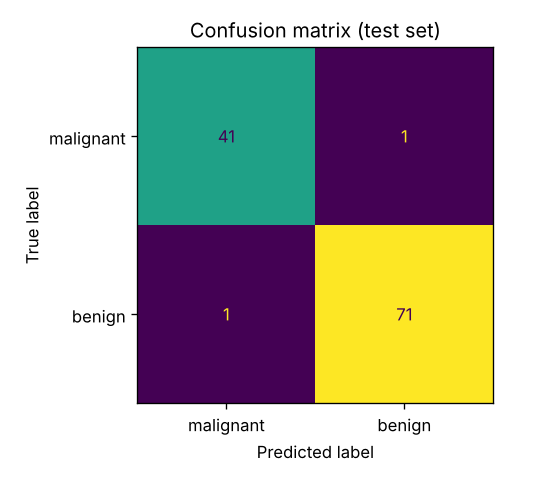

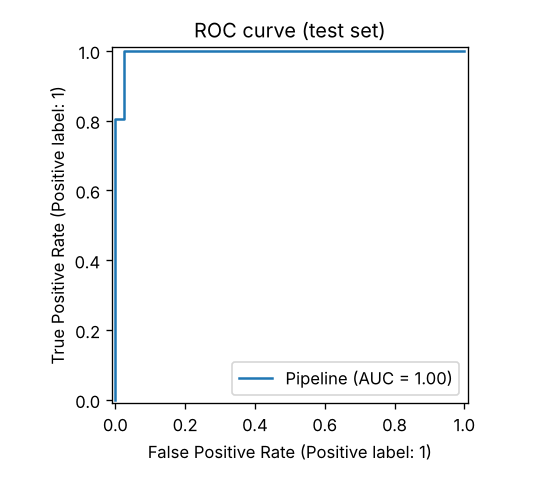

In [18]:
import pandas as pd
from IPython.display import Image, display
display(pd.read_csv('reports/model_comparison.csv').round(4))
display(Image('reports/confusion_matrix.png'), Image('reports/roc_curve.png'))

**Interpreting:** the confusion matrix rows are true classes. Off-diagonal cells are mistakes; the one that matters most is a malignant tumour predicted benign. ROC-AUC near 1.0 means the model ranks malignant cases above benign ones almost perfectly. With only 114 test samples, one extra mistake moves accuracy by about 0.9 points, so treat the numbers as indicative.

## 6. Run predictions

In [19]:
from bcclf.predict import load_artifact, predict_records
from bcclf.data import load_dataset
art = load_artifact()
X, y, names = load_dataset()
for i in (0, 19):
    print('true:', names[y[i]], '->', predict_records(art, [X.iloc[i].to_dict()])[0])

2026-11-08 16:19:47,600 | INFO     | bcclf.data | Loaded dataset: 569 rows, 30 features


true: malignant -> {'prediction': 'malignant', 'probabilities': {'malignant': 1.0, 'benign': 0.0}}
true: benign -> {'prediction': 'benign', 'probabilities': {'malignant': 0.0854, 'benign': 0.9146}}


## 7. Test the API
Uses FastAPI's in-process test client (no network port needed in Colab).

In [20]:
from fastapi.testclient import TestClient
from bcclf.api import app
with TestClient(app) as client:
    print(client.get('/health').json())
    r = client.post('/predict', json={'features': X.iloc[0].to_dict()})
    print(r.status_code, r.json())
    bad = client.post('/predict', json={'features': {'mean radius': 1.0}})
    print(bad.status_code, bad.json())

/usr/local/lib/python3.12/dist-packages/fastapi/testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa
2026-11-08 16:19:47,889 | INFO     | bcclf.api | Model 'logistic_regression' loaded


2026-11-08 16:19:47,893 | INFO     | httpx | HTTP Request: GET http://testserver/health "HTTP/1.1 200 OK"


2026-11-08 16:19:47,898 | INFO     | httpx | HTTP Request: POST http://testserver/predict "HTTP/1.1 200 OK"


2026-11-08 16:19:47,901 | INFO     | httpx | HTTP Request: POST http://testserver/predict "HTTP/1.1 422 Unprocessable Entity"


{'status': 'ok', 'model': 'logistic_regression'}
200 {'prediction': 'malignant', 'probabilities': {'malignant': 1.0, 'benign': 0.0}}
422 {'detail': "Record 0 is missing features: ['mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']"}


## 8. Common problems

| Symptom | Cause | Fix |
|---|---|---|
| `ModuleNotFoundError: bcclf` | `sys.path` cell not run | Re-run section 1 |
| `FileNotFoundError: Model not found` | Training not run | Run section 4 |
| HTTP 422 from `/predict` | Missing or non-numeric feature | Call `/features` for the exact names |
| Different numbers than shown | Library version or seed changed | Keep `RANDOM_STATE=42` |

## 9. Requirements checklist
Data loading and validation, stratified split, model comparison, evaluation with plots, saved artifact, inference, REST API, automated tests: all executed above.

**Limitations:** small dataset; single hold-out split; threshold not tuned for recall; no explainability. **Next steps:** repeated CV, threshold tuning, SHAP, Docker, CI.